[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/sklearn-evaluation.ipynb)

# scikit-learn: Evaluation and Imbalanced Classes

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Read a confusion matrix and choose between precision, recall and F1.</li>
<li>Use ROC and precision-recall curves, and pick a threshold from costs without touching the test set.</li>
<li>Check calibration and know what class weights do and do not do.</li>
<li>Report cross-validated spread, and evaluate a regression against a baseline.</li>
</ul>
</div>

**Prerequisites:** <a href="../sklearn-models/">scikit-learn: Model Families</a>. **Dataset:** Credit Card Default and Inside Airbnb. **Time:** about 50 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_credit, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.3f}".format)

## The situation

"Accuracy" is the metric everyone reaches for and the one most likely to mislead. Choosing how to evaluate a model is really choosing **what a mistake costs**. This page works through the evaluation toolkit on a problem where it matters: predicting credit default, where only about one customer in five defaults and the two kinds of error are very different.

We use a gradient-boosted model, a held-out test set for the final numbers, and cross-validated predictions on the training data for any *decision* (like choosing a threshold) so the test set stays untouched.

In [2]:
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.ensemble import HistGradientBoostingClassifier

credit = load_credit()
y = credit["default payment next month"]
X = credit.drop(columns=["ID", "default payment next month"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

model = HistGradientBoostingClassifier(random_state=0)
oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]       # out-of-fold probabilities for every training row
model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
print(f"default rate: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

default rate: train 22.1%, test 22.1%


## 1. The confusion matrix and what it hides

Every classification result is four counts: true and false positives and negatives. At the default threshold of 0.5:

In [3]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

pred = (p_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
cm = pd.DataFrame([[tn, fp], [fn, tp]], index=["actually fine", "actually defaulted"], columns=["predicted fine", "predicted default"])
print(cm.to_string())
print(f"\naccuracy: {accuracy_score(y_test, pred):.3f};  but of the {fn + tp:,} customers who really defaulted, the model caught only {tp:,} ({tp / (fn + tp):.0%})")
print(classification_report(y_test, pred, target_names=["fine", "default"], digits=3))

                    predicted fine  predicted default
actually fine                 5562                279
actually defaulted            1069                590

accuracy: 0.820;  but of the 1,659 customers who really defaulted, the model caught only 590 (36%)
              precision    recall  f1-score   support

        fine      0.839     0.952     0.892      5841
     default      0.679     0.356     0.467      1659

    accuracy                          0.820      7500
   macro avg      0.759     0.654     0.679      7500
weighted avg      0.803     0.820     0.798      7500



**Reading it.** Accuracy looks respectable at 82%, but read the bottom row: of the 1,659 customers who really defaulted, the model caught 590 (36%) and missed 1,069. Precision is decent (68% of the customers it flagged really do default) while recall is poor. Accuracy was flattered by the 5,841 easy "fine" customers, which is the accuracy trap from the first page, now with real numbers.

The metrics, in plain words:

| Metric | Question it answers | Formula |
|---|---|---|
| **Precision** | of those we *flagged*, how many really defaulted? | TP / (TP + FP) |
| **Recall** (sensitivity) | of those who *defaulted*, how many did we catch? | TP / (TP + FN) |
| **F1** | a single number balancing the two | harmonic mean of precision and recall |
| **Specificity** | of those who were *fine*, how many did we leave alone? | TN / (TN + FP) |

## 2. Curves instead of a single threshold

Both precision and recall depend on the **threshold** (the probability above which we say "default"). Rather than fix one, plot what happens at *every* threshold. Two curves do this:

- **ROC curve:** true-positive rate against false-positive rate. **AUC** is the area under it: the probability that a random defaulter is scored above a random non-defaulter (0.5 = chance).
- **Precision-recall curve:** precision against recall. **Average precision** summarises it.

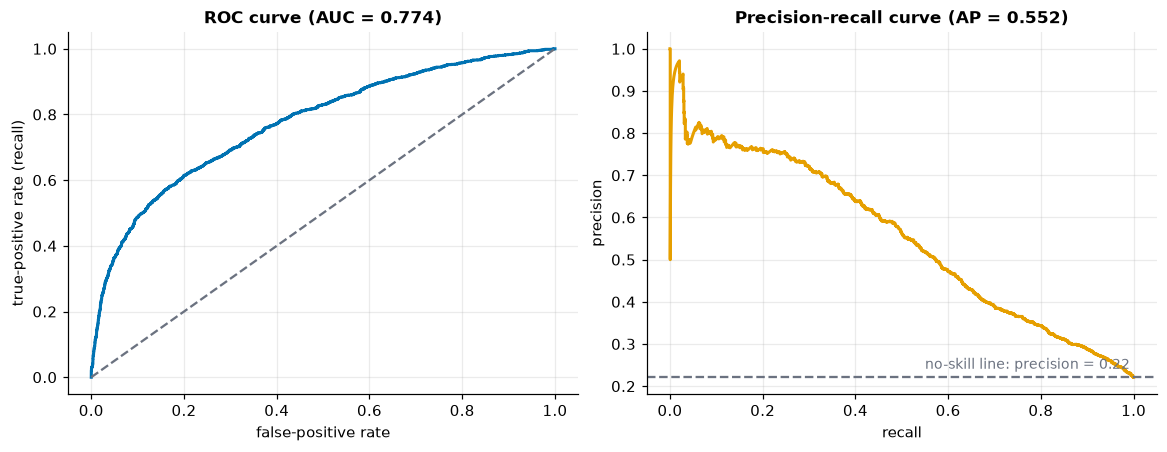

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fpr, tpr, _ = roc_curve(y_test, p_test)
prec, rec, _ = precision_recall_curve(y_test, p_test)
fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 4), constrained_layout=True)
a.plot(fpr, tpr, color=style.BLUE, lw=2); a.plot([0, 1], [0, 1], color=style.GREY, ls="--")
a.set(title=f"ROC curve (AUC = {roc_auc_score(y_test, p_test):.3f})", xlabel="false-positive rate", ylabel="true-positive rate (recall)")
b.plot(rec, prec, color=style.ORANGE, lw=2); b.axhline(y_test.mean(), color=style.GREY, ls="--")
b.set(title=f"Precision-recall curve (AP = {average_precision_score(y_test, p_test):.3f})", xlabel="recall", ylabel="precision")
b.text(0.55, y_test.mean() + 0.02, f"no-skill line: precision = {y_test.mean():.2f}", color=style.GREY, fontsize=9)
plt.show()

**Reading the curves.** The ROC curve bows comfortably above the diagonal (AUC 0.774): most of the time the model scores a real defaulter above a real non-defaulter. The precision-recall curve is the more sobering view. Precision is high (around 0.75) for the first customers flagged, then falls steadily as you flag more people to catch more defaulters, ending at the dashed no-skill line (0.22, the base rate) when you flag everyone. **A threshold simply chooses a point on that curve.** (The wobble at the far left is a handful of very confident predictions; at the extremes a few customers swing the curve.)

## 3. Choosing a threshold from the costs

A threshold is a **decision**, and a decision needs costs. Suppose (an assumption for illustration, which in real life comes from the business) that missing a defaulter costs five times as much as wrongly flagging a good customer. Then flagging is worthwhile whenever the probability of default exceeds 1 in 6, much lower than 0.5. We choose the threshold on the **cross-validated training predictions**, never on the test set:

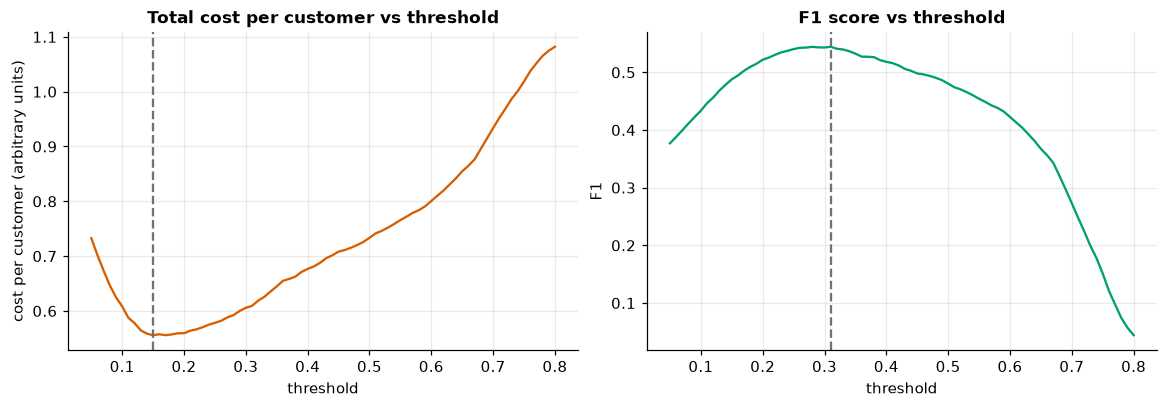

threshold that minimises cost (5:1): 0.15;  threshold that maximises F1: 0.31;  the default is 0.50


In [5]:
COST_MISSED, COST_FALSE_ALARM = 5.0, 1.0          # illustrative assumption: a missed defaulter costs 5x a false alarm
thresholds = np.linspace(0.05, 0.8, 76)

def total_cost(truth, scores, t):
    flagged = scores >= t
    return COST_MISSED * ((~flagged) & (truth == 1)).sum() + COST_FALSE_ALARM * (flagged & (truth == 0)).sum()

cost_curve = np.array([total_cost(y_train.to_numpy(), oof, t) for t in thresholds])
f1 = np.array([2 * ((oof >= t) & (y_train == 1)).sum() / (2 * ((oof >= t) & (y_train == 1)).sum() + ((oof >= t) & (y_train == 0)).sum() + ((oof < t) & (y_train == 1)).sum()) for t in thresholds])
best_cost_t, best_f1_t = thresholds[cost_curve.argmin()], thresholds[f1.argmax()]

fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True)
a.plot(thresholds, cost_curve / len(y_train), color=style.RED); a.axvline(best_cost_t, color=style.GREY, ls="--")
a.set(title="Total cost per customer vs threshold", xlabel="threshold", ylabel="cost per customer (arbitrary units)")
b.plot(thresholds, f1, color=style.GREEN); b.axvline(best_f1_t, color=style.GREY, ls="--"); b.set(title="F1 score vs threshold", xlabel="threshold", ylabel="F1")
plt.show()
print(f"threshold that minimises cost (5:1): {best_cost_t:.2f};  threshold that maximises F1: {best_f1_t:.2f};  the default is 0.50")

In [6]:
def report(t):
    flagged = p_test >= t
    tp, fp = (flagged & (y_test == 1)).sum(), (flagged & (y_test == 0)).sum()
    return {"threshold": t, "flagged": int(flagged.sum()), "precision": tp / flagged.sum(), "recall": tp / y_test.sum(), "cost on test": total_cost(y_test.to_numpy(), p_test, t)}
pd.DataFrame([report(0.5), report(best_f1_t), report(best_cost_t)], index=["default 0.5", "max-F1 threshold", "cost-minimising threshold"]).round(3)

,threshold,flagged,precision,recall,cost on test
default 0.5,0.500,869,0.679,0.356,"5,624.000"
max-F1 threshold,0.310,1586,0.545,0.521,"4,691.000"
cost-minimising threshold,0.150,3505,0.360,0.761,"4,222.000"


**Reading the table.** Lowering the threshold from 0.5 to 0.15 roughly doubles the share of defaulters caught (36% to 76%), at the price of flagging four times as many customers and much lower precision (68% to 36%). Under the assumed 5-to-1 costs that is the right trade: total cost on the test set falls by about a quarter (5,624 to 4,222).

Two details. The cost-minimising threshold (0.15) sits very close to the textbook break-even point `1 / (1 + 5) = 0.167`: for well-calibrated probabilities, *the best threshold is just the cost ratio*. And the F1-maximising threshold (0.31) is a compromise that implicitly weighs the two errors roughly equally; **F1 does not know your costs.** The thresholds were chosen on training data and judged once on the test set, so these test numbers are honest.

## 4. Class weights: moving the decision, not the ranking

Instead of moving the threshold you can tell the model to take the rare class more seriously, with `class_weight="balanced"`. This changes the *fitting*, so predictions at 0.5 become more eager to flag defaulters. But it re-shapes the probabilities, it does not make the model rank customers better.

In [7]:
balanced = HistGradientBoostingClassifier(class_weight="balanced", random_state=0).fit(X_train, y_train)
p_bal = balanced.predict_proba(X_test)[:, 1]
rows = {}
for name, p in [("unweighted", p_test), ("class_weight='balanced'", p_bal)]:
    flagged = p >= 0.5
    rows[name] = {"AUC (ranking)": roc_auc_score(y_test, p), "recall at 0.5": ((flagged) & (y_test == 1)).sum() / y_test.sum(), "precision at 0.5": ((flagged) & (y_test == 1)).sum() / flagged.sum(), "average predicted probability": p.mean()}
pd.DataFrame(rows).T.round(3)

,AUC (ranking),recall at 0.5,precision at 0.5,average predicted probability
unweighted,0.774,0.356,0.679,0.218
class_weight='balanced',0.774,0.617,0.463,0.410


**Reading the table.** The AUC is identical (0.774): class weighting did not make the model better at *ranking*. It moved the operating point: at 0.5, recall rises from 36% to 62% while precision falls from 68% to 46%, the same kind of trade as lowering the threshold. And look at the last column: the balanced model's average predicted probability is 0.41 although only 22% of customers default. It has stopped producing probabilities and started producing *scores*.

## 5. Are the probabilities trustworthy? Calibration

If a model says 30%, do about 30% of those customers default? A **reliability diagram** groups customers by predicted probability and compares with reality. The **Brier score** (mean squared error of the probabilities, lower is better) summarises it.

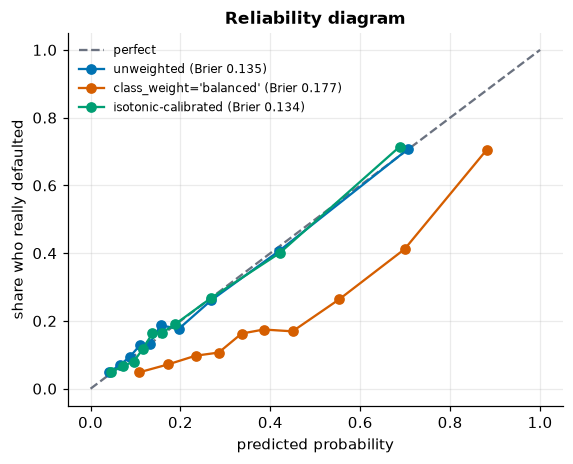

In [8]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

calibrated = CalibratedClassifierCV(HistGradientBoostingClassifier(random_state=0), method="isotonic", cv=5).fit(X_train, y_train)
p_cal = calibrated.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5.8, 4.4))
ax.plot([0, 1], [0, 1], color=style.GREY, ls="--", label="perfect")
for name, p, color in [("unweighted", p_test, style.BLUE), ("class_weight='balanced'", p_bal, style.RED), ("isotonic-calibrated", p_cal, style.GREEN)]:
    obs, pred_mean = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(pred_mean, obs, marker="o", color=color, label=f"{name} (Brier {brier_score_loss(y_test, p):.3f})")
ax.set(xlabel="predicted probability", ylabel="share who really defaulted", title="Reliability diagram"); ax.legend(fontsize=8)
plt.show()

**Reading the diagram.** The unweighted model hugs the diagonal: when it says 40%, about 40% of those customers default (Brier 0.135). Gradient boosting trained with its usual loss is well calibrated here, so isotonic calibration changes almost nothing (0.134); there was little to fix. The class-weighted model sits far below the diagonal (when it says 70%, the truth is about 40%) and its Brier score is clearly worse (0.177). Calibration is not automatic: it depends on the model and how it was trained, so check before quoting a probability.

## 6. How sure are you? Cross-validation with spread

One train/test split gives one number. Cross-validation gives several, and their **spread** tells you how much to trust the average. Use `cross_validate` to collect several metrics at once:

In [9]:
from sklearn.model_selection import cross_validate
res = cross_validate(HistGradientBoostingClassifier(random_state=0), X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision", "neg_brier_score"], n_jobs=-1)
summary = pd.DataFrame({"mean": [res["test_roc_auc"].mean(), res["test_average_precision"].mean(), -res["test_neg_brier_score"].mean()],
                        "std across folds": [res["test_roc_auc"].std(), res["test_average_precision"].std(), res["test_neg_brier_score"].std()]},
                       index=["AUC", "average precision", "Brier score"])
summary.round(4)

,mean,std across folds
AUC,0.781,0.007
average precision,0.558,0.009
Brier score,0.134,0.002


**Reading the table.** Across the five folds the AUC averages 0.781 with a standard deviation of 0.007, and the test AUC (0.774) is within that spread, so the held-out result is consistent with cross-validation. The spread also tells you something practical: **a difference of a few thousandths between two models is inside the noise.** Never rank models on a single split.

## 7. Regression has its own metrics

For predicting a *number*, the common measures are **MAE** (average absolute error, in the units of the target), **RMSE** (penalises large errors more) and **R²** (the share of variance explained; 0 means no better than predicting the mean). Always compare against a baseline that predicts a constant. Here, nightly Airbnb price from listing size and type:

In [10]:
from mlp_data import load_airbnb
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ab = load_airbnb()
ab = ab.assign(price=pd.to_numeric(ab["price"].str.replace(r"[$,]", "", regex=True), errors="coerce"))
ab = ab[ab["price"].between(10, 2000) & ab["room_type"].isin(["Entire home/apt", "Private room"])].dropna(subset=["bedrooms", "beds"])
feats = ["accommodates", "bedrooms", "beds", "number_of_reviews", "availability_365", "room_type", "neighbourhood_cleansed"]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(ab[feats], ab["price"], test_size=0.25, random_state=0)

prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["room_type", "neighbourhood_cleansed"])], remainder="passthrough")
models = {"predict the median": DummyRegressor(strategy="median"),
          "ridge regression (log price)": TransformedTargetRegressor(make_pipeline(prep, Ridge(1.0)), func=np.log, inverse_func=np.exp)}
rows = {}
for name, m in models.items():
    p = m.fit(Xa_train, ya_train).predict(Xa_test)
    rows[name] = {"MAE (£)": mean_absolute_error(ya_test, p), "RMSE (£)": np.sqrt(mean_squared_error(ya_test, p)), "R-squared": r2_score(ya_test, p)}
print(f"{len(Xa_train):,} training listings, {len(Xa_test):,} test listings; median price £{ya_train.median():.0f}")
pd.DataFrame(rows).T.round(2)

43,362 training listings, 14,454 test listings; median price £175


,MAE (£),RMSE (£),R-squared
predict the median,122.350,204.360,-0.060
ridge regression (log price),77.310,149.870,0.430


**Reading the table.** Predicting the median price gives an R² slightly below zero (−0.06: marginally *worse* than predicting the mean, which is defined as 0) and a typical error of about £122. The ridge regression on the log of price cuts the typical error to about £77 and explains 43% of the variance. That is genuine progress, but a typical miss of £77 on a median price of £175 is still large: size, room type and area explain well under half of what makes one listing pricier than another. RMSE is larger than MAE because big misses on expensive listings are squared. (We modelled the log of price and converted back, so the model's errors scale with the price rather than being a fixed number of pounds.)

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| 78% accuracy, finds nothing | class imbalance | precision, recall, PR curve; compare with a dummy |
| ROC AUC looks great, precision is poor | ROC hides the effect of many negatives | look at the PR curve on rare-event problems |
| Chose a threshold on the test set | the test is no longer independent | pick it on cross-validated training predictions |
| `class_weight` "improved" AUC | it did not; it changed the probabilities | judge ranking with AUC, decisions with a cost-based threshold |
| "Probability of 0.3" is not 30% | uncalibrated scores | reliability diagram; `CalibratedClassifierCV` |
| One split, one number | no uncertainty | cross-validate; report mean and spread |

## Check yourself

<details class="question">
<summary>1. A fraud model has 99% accuracy on data where 1% of transactions are fraud. Is it good?</summary>

Not necessarily: a model that never flags anything also scores 99%. Ask for recall (what share of frauds were caught) and precision (what share of alerts were real), and compare against that do-nothing baseline.

</details>

<details class="question">
<summary>2. When would you prefer the precision-recall curve to the ROC curve?</summary>

When the positive class is rare. The ROC curve's false-positive *rate* divides by the large number of negatives, so even many false alarms keep it looking small; precision divides by the number of alerts, so a flood of false positives shows up immediately. For rare-event problems the PR curve is the more honest picture.

</details>

<details class="question">
<summary>3. Why choose the decision threshold on cross-validated <em>training</em> predictions rather than on the test set?</summary>

The threshold is a fitted choice. If you tune it on the test set, the test score is no longer an independent estimate: it has been optimised for exactly those rows. Cross-validated out-of-fold predictions are honest (each was made by a model that did not see that row), so you can choose on them and still evaluate once on the untouched test set.

</details>

## Exercises

<details class="question">
<summary>How does the best threshold change if a missed defaulter costs 10 times a false alarm instead of 5? Predict first, then re-run the cost curve.</summary>

```python
COST_MISSED = 10.0
cost_curve = np.array([total_cost(y_train.to_numpy(), oof, t) for t in thresholds])
print(thresholds[cost_curve.argmin()])
```

The break-even probability is `cost_false_alarm / (cost_false_alarm + cost_missed)`, which falls from 1/6 to 1/11, so the best threshold moves **lower**: with the 5:1 ratio it was about 0.15, and with 10:1 it falls to about 0.08, tracking the break-evens of 1/6 and 1/11. When a miss is dearer you flag more customers. (Remember to restore `COST_MISSED = 5.0` afterwards.)

</details>

<details class="question">
<summary>Compute the <em>average predicted probability</em> and the actual default rate on the test set for each of the three models. What does the comparison reveal about <code>class_weight</code>?</summary>

```python
for name, p in [("unweighted", p_test), ("balanced", p_bal), ("calibrated", p_cal)]:
    print(f"{name:12s} mean predicted {p.mean():.3f}  vs actual {y_test.mean():.3f}")
```

The unweighted and calibrated models average about 0.22, matching the true 22%. The balanced model averages about 0.41, because reweighting the classes shifts every probability upward: its numbers are no longer probabilities of default, which is why `class_weight` is a tool for *decisions at a threshold*, not for honest probabilities.

</details>

## Recap

- **Accuracy misleads** on imbalanced data; use precision, recall, F1, and compare with a dummy baseline.
- ROC/AUC measures **ranking**; the **precision-recall** curve is the honest view for rare positives.
- A threshold is a **decision**: choose it from costs, on cross-validated training predictions, never on the test set.
- `class_weight` changes the decision point and distorts probabilities; it does not improve ranking.
- Check **calibration** (reliability diagram, Brier score) before trusting a probability; calibrate if needed.
- Report **cross-validated spread**, not a single number. For regression use MAE/RMSE/R² against a constant baseline.

**Next:** *Unsupervised learning*, finding structure without a target.